# LoomIQ 04 · Modelling and Explainability

Train models that predict **whether a team will meet its daily target**, pick the best one honestly, and explain its predictions with SHAP.

Reusable code: `src/loomiq/models/` (`train_productivity.py`, `predict.py`, `explain.py`).

## Goals

1. Split the data so the test is an honest "predict the future" check
2. Compare a baseline, logistic regression, random forest and XGBoost with cross-validation
3. Evaluate the best model on the held-out weeks, overall and per department
4. Check whether incentive should be used (leakage question from notebook 02)
5. Explain the model with SHAP, globally and for one line
6. Save the model for the dashboard

In [1]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from loomiq.config import get_path, load_config
from loomiq.data.clean import load_clean_productivity
from loomiq.features.build_features import build_features
from loomiq.models import explain, predict
from loomiq.models.train_productivity import time_based_split, train_productivity_model
from loomiq.utils.plotting import (
    DEPARTMENT_COLORS, NEUTRAL, STATUS_COLORS, TEXT_SECONDARY, apply_style, save_figure,
)

config = load_config()
params = config["productivity_model"]
apply_style()
pd.set_option("display.max_columns", 50)

df = load_clean_productivity()

## 1. Split by time

A random split would put days from the same week in both train and test, so the model could "peek" at neighbouring days. In real use the model always predicts **days it has never seen, after the days it learned from**. So the **last 20% of dates** are the test set.

In [2]:
train_df, test_df = time_based_split(df, params["test_size"])
split = pd.DataFrame({
    "from": [train_df["date"].min().date(), test_df["date"].min().date()],
    "to": [train_df["date"].max().date(), test_df["date"].max().date()],
    "rows": [len(train_df), len(test_df)],
    "met_rate": [
        (train_df["actual_productivity"] >= train_df["targeted_productivity"]).mean(),
        (test_df["actual_productivity"] >= test_df["targeted_productivity"]).mean(),
    ],
}, index=["train", "test"])
split.style.format({"met_rate": "{:.1%}"})

,from,to,rows,met_rate
train,2015-01-01,2015-02-25,943,73.0%
test,2015-02-26,2015-03-11,254,73.2%


## 2. How we score models

73% of days are "met", so a model that **always says met** is 73% accurate and completely useless: it never warns about a single at-risk line.

The manager cares about **catching the misses**, so the main metric is **F1 for the "missed target" class**:
- **Precision (missed):** when the model warns "this line will miss", how often is it right?
- **Recall (missed):** of the lines that really missed, how many did the model catch?
- **F1:** a balance of the two (0 = useless, 1 = perfect).

ROC-AUC and accuracy are reported too.

## 3. Compare models with cross-validation

5-fold stratified cross-validation **on the training weeks only** picks the best model. The test weeks stay untouched until the end.

`train_productivity_model` runs the whole pipeline (split, features, CV, refit the best model, test, save). Incentive is **off**, as set in config.

In [3]:
result = train_productivity_model(df, use_incentive=False, save=True)
cv_table = pd.DataFrame({r.name: r.cv_scores for r in result.all_results}).T
cv_table = cv_table[["missed_f1", "missed_precision", "missed_recall", "roc_auc", "accuracy"]]
cv_table.style.format("{:.3f}").highlight_max(subset=["missed_f1"], color="#cde2fb")

2026-10-30 19:36:05 | INFO     | loomiq.models.train_productivity | Train: 943 rows up to 2015-02-25 | Test: 254 rows from 2015-02-26


2026-10-30 19:36:07 | INFO     | loomiq.models.train_productivity | CV baseline             missed F1 = 0.000


2026-10-30 19:36:07 | INFO     | loomiq.models.train_productivity | CV logistic_regression  missed F1 = 0.528


2026-10-30 19:36:12 | INFO     | loomiq.models.train_productivity | CV random_forest        missed F1 = 0.596


2026-10-30 19:36:14 | INFO     | loomiq.models.train_productivity | CV xgboost              missed F1 = 0.613


2026-10-30 19:36:15 | INFO     | loomiq.models.train_productivity | Best model: xgboost | test missed F1 = 0.500


2026-10-30 19:36:15 | INFO     | loomiq.models.train_productivity | Saved model to D:\Projects\LoomIQ\LoomIQ-Garment-Factory-Intelligence-Platform\models\productivity_model.joblib


2026-10-30 19:36:15 | INFO     | loomiq.models.train_productivity | Saved metrics to D:\Projects\LoomIQ\LoomIQ-Garment-Factory-Intelligence-Platform\reports\productivity_metrics.json


,missed_f1,missed_precision,missed_recall,roc_auc,accuracy
baseline,0.000,0.000,0.000,0.500,0.730
logistic_regression,0.528,0.442,0.663,0.734,0.679
random_forest,0.596,0.520,0.706,0.821,0.739
xgboost,0.613,0.561,0.678,0.835,0.769


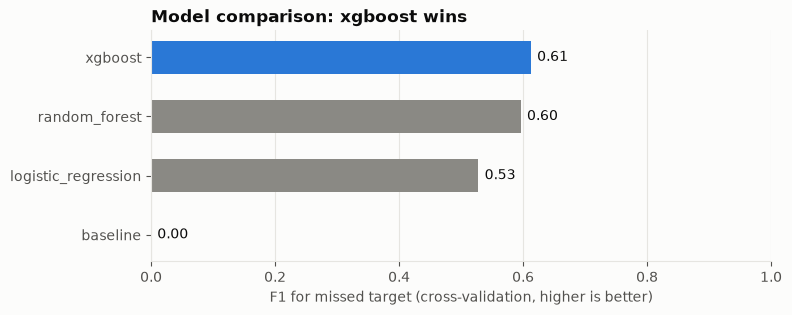

In [4]:
fig, ax = plt.subplots(figsize=(8, 3))
order = cv_table["missed_f1"].sort_values().index
colors = [DEPARTMENT_COLORS["sewing"] if name == result.best.name else NEUTRAL for name in order]
ax.barh(order, cv_table.loc[order, "missed_f1"], color=colors, height=0.55)
for y, value in enumerate(cv_table.loc[order, "missed_f1"]):
    ax.text(value + 0.01, y, f"{value:.2f}", va="center")
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("F1 for missed target (cross-validation, higher is better)")
ax.set_title(f"Model comparison: {result.best.name} wins")
save_figure(fig, "model_01_cv_comparison")
plt.show()

**Findings**
- The baseline scores **0**: it never predicts a miss, which proves accuracy alone would have fooled us.
- The tree models (XGBoost and random forest) beat logistic regression, so the relationships are not just straight lines. XGBoost wins narrowly.

## 4. Test on the held-out weeks

In [5]:
scores = {k: v for k, v in result.test_metrics.items() if k != "confusion_matrix"}
test = pd.DataFrame(scores).T
test = test[["rows", "missed_f1", "missed_precision", "missed_recall", "roc_auc", "accuracy"]].astype(float)
test.style.format("{:.3f}").format("{:.0f}", subset=["rows"])

,rows,missed_f1,missed_precision,missed_recall,roc_auc,accuracy
overall,254,0.500,0.427,0.603,0.722,0.677
finishing,115,0.613,0.586,0.642,0.683,0.626
sewing,139,0.264,0.184,0.467,0.674,0.719


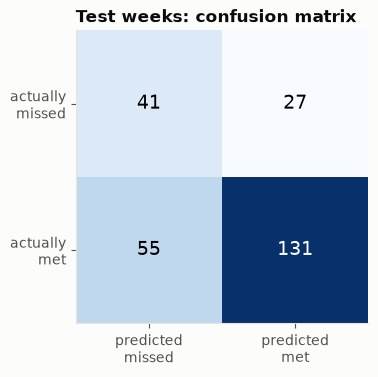

In [6]:
cm = np.array(result.test_metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(4.5, 3.8))
ax.imshow(cm, cmap="Blues")
labels = ["missed", "met"]
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], [f"predicted\n{l}" for l in labels])
ax.set_yticks([0, 1], [f"actually\n{l}" for l in labels])
ax.grid(False)
ax.set_title("Test weeks: confusion matrix")
save_figure(fig, "model_02_confusion_matrix")
plt.show()

**Findings**
- On the unseen weeks the model catches about **60% of the real misses** (recall). When it raises a warning, it is right about **43%** of the time (precision). That is 1.6 times better than warning at random: only 27% of days are misses.
- **Finishing** is predicted reasonably well (missed F1 ≈ 0.61). **Sewing** is weak (≈ 0.26): there are few sewing misses in the test weeks, and they are hard to tell apart from normal days.
- **Test scores are lower than cross-validation** (missed F1 0.50 vs 0.61). Cross-validation shuffles days from all weeks together, which is slightly optimistic. The time-based test shows how the factory changes from week to week. **The test number is the honest one** to report.

## 5. Should we use incentive?

Notebook 02 found incentive may be paid **because** a team hit its target. If so, using it leaks the answer. Train again with incentive switched on and compare (nothing is saved this time).

In [7]:
with_incentive = train_productivity_model(df, use_incentive=True, save=False)
compare = pd.DataFrame({
    "without incentive (default)": {
        "best model": result.best.name,
        "CV missed F1": result.best.cv_scores["missed_f1"],
        "test missed F1": result.test_metrics["overall"]["missed_f1"],
        "test ROC-AUC": result.test_metrics["overall"]["roc_auc"],
    },
    "with incentive": {
        "best model": with_incentive.best.name,
        "CV missed F1": with_incentive.best.cv_scores["missed_f1"],
        "test missed F1": with_incentive.test_metrics["overall"]["missed_f1"],
        "test ROC-AUC": with_incentive.test_metrics["overall"]["roc_auc"],
    },
})
compare

2026-10-30 19:36:16 | INFO     | loomiq.models.train_productivity | Train: 943 rows up to 2015-02-25 | Test: 254 rows from 2015-02-26


2026-10-30 19:36:16 | INFO     | loomiq.models.train_productivity | CV baseline             missed F1 = 0.000


2026-10-30 19:36:16 | INFO     | loomiq.models.train_productivity | CV logistic_regression  missed F1 = 0.610


2026-10-30 19:36:25 | INFO     | loomiq.models.train_productivity | CV random_forest        missed F1 = 0.620


2026-10-30 19:36:29 | INFO     | loomiq.models.train_productivity | CV xgboost              missed F1 = 0.640


2026-10-30 19:36:30 | INFO     | loomiq.models.train_productivity | Best model: xgboost | test missed F1 = 0.506


,without incentive (default),with incentive
best model,xgboost,xgboost
CV missed F1,0.612629,0.639976
test missed F1,0.5,0.506494
test ROC-AUC,0.721695,0.76265


**Decision: keep incentive out.**
- Adding incentive gives only a **small gain** on the honest future test (missed F1 0.51 vs 0.50, ROC-AUC 0.76 vs 0.72), even though notebook 02 showed it is the single strongest correlation in the data. A feature that strongly correlated but barely helps predict *future* weeks is consistent with it being a **reward recorded after the fact**, not a cause known in advance.
- Including it would risk a model that looks better on paper but can't be used during the shift, when the day's incentive isn't known yet.
- The switch stays in `configs/config.yaml` (`use_incentive`) in case the factory confirms incentives are set in advance.

## 6. Explain the model with SHAP

SHAP splits each prediction into contributions from each input. In LoomIQ, **positive = pushes the line towards missing its target**. One-hot columns are added back together, so "team" is one factor instead of eleven columns.

In [8]:
bundle = predict.load_model()
X_train, _ = build_features(train_df, bundle["use_incentive"])
X_test = predict.prepare_features(bundle, test_df)

explainer = explain.build_explainer(bundle["model"], X_train)
importance = explain.global_importance(explainer, X_test)
importance.head(10)

,feature,label,mean_abs_shap
0,wip,work in progress,0.527675
1,no_of_workers,team size,0.501716
2,smv,SMV (garment complexity),0.476653
3,day,day of week,0.441272
4,overtime_per_worker,overtime per worker,0.440651
5,team,team,0.408586
6,targeted_productivity,target level,0.393191
7,quarter,week of month,0.341836
8,wip_per_worker,WIP per worker,0.308225
9,over_time,overtime minutes,0.195250


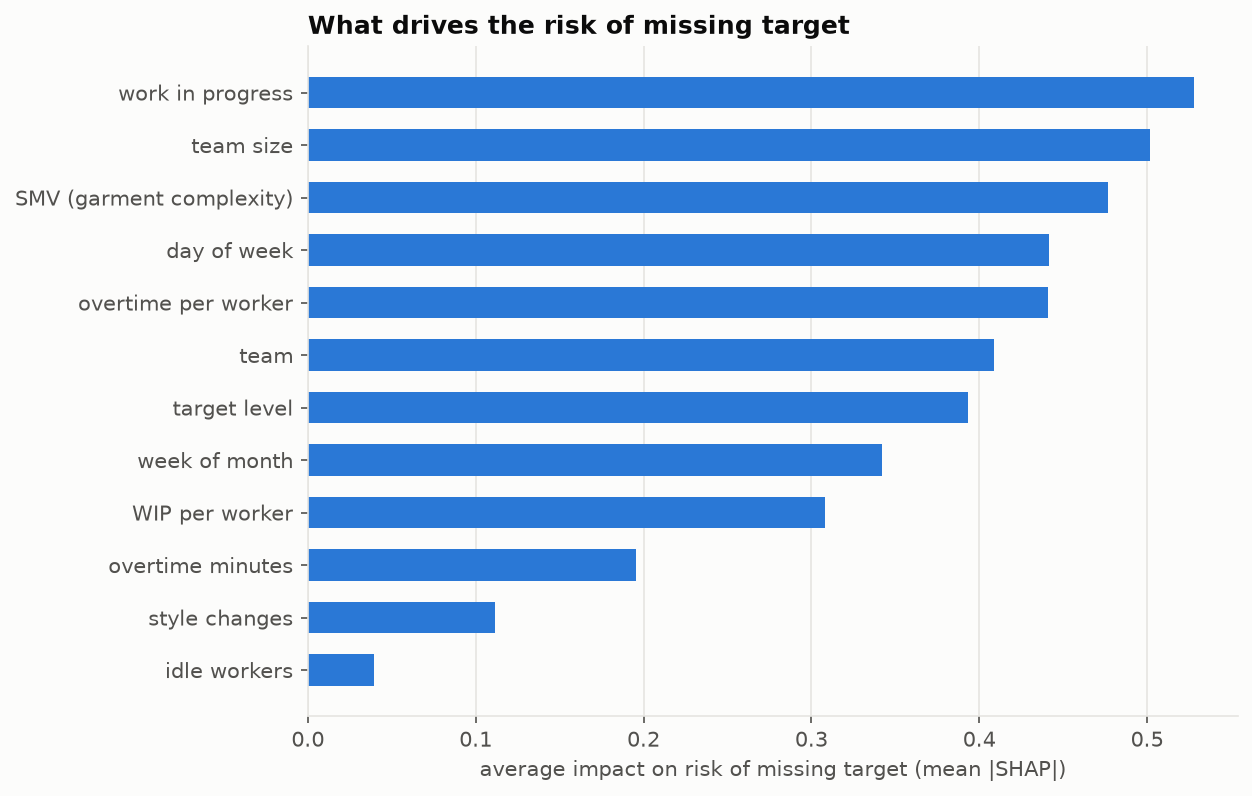

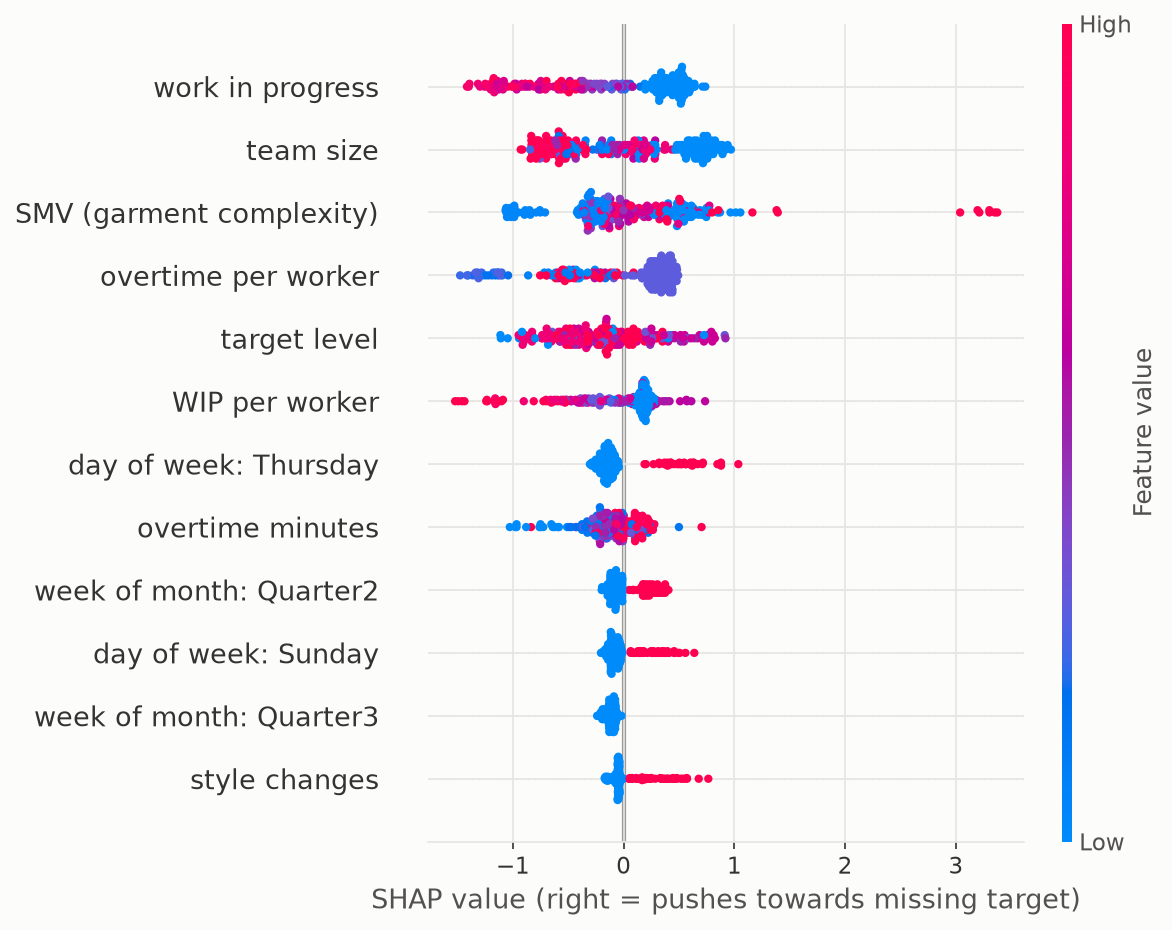

In [9]:
figures = get_path("figures")
explain.save_importance_plot(importance, figures / "shap_importance.png")
explain.save_summary_plot(explainer, X_test, figures / "shap_summary.png")

display(Image(figures / "shap_importance.png", width=650))
display(Image(figures / "shap_summary.png", width=650))

**How to read the beeswarm:** each dot is one team-day in the test weeks. Dots to the **right** pushed that day towards **missing** the target. Red means a high value of that feature, blue a low one.

**Findings**
- **Work in progress, team size and SMV** matter most. Low WIP and small teams (both typical of **finishing**) push towards missing, which matches finishing's lower met rate in notebook 02.
- **Very high SMV** (complex garments) can push a sewing line strongly towards missing: the dots far to the right.
- **Day of week** ranks high, mainly through **Thursday**, which notebook 02 also showed as the weakest day. With only 10 weeks of data this may be partly coincidence, so it is worth re-checking when more data arrives.
- **Idle time is absent** from the chart because no idle events happened in the test weeks, not because it doesn't matter.

## 7. Explain one line: "Why is this line at risk?"

This is exactly what the dashboard and the AI assistant will show: the top reasons for one line's risk.

In [10]:
predictions = predict.predict_line(bundle, test_df)
predictions["actually_met"] = (predictions["actual_productivity"] >= predictions["targeted_productivity"]).astype(int)
riskiest = predictions.sort_values("risk_probability", ascending=False)
riskiest[["date", "department", "team", "targeted_productivity", "actual_productivity",
          "risk_probability", "met_target_pred", "actually_met"]].head(5)

,date,department,team,targeted_productivity,actual_productivity,risk_probability,met_target_pred,actually_met
1145,2015-03-09,sewing,8,0.65,0.650421,0.993148,0,1
1147,2015-03-09,sewing,7,0.50,0.500611,0.990926,0,1
1123,2015-03-08,sewing,8,0.60,0.600529,0.989532,0,1
1191,2015-03-11,sewing,7,0.65,0.650596,0.986235,0,1
1169,2015-03-10,sewing,7,0.60,0.630403,0.985660,0,1


In [11]:
line = riskiest.iloc[[0]]
print(f"{line['date'].dt.date.iloc[0]} | {line['department'].iloc[0]} team {line['team'].iloc[0]} | "
      f"risk of missing = {line['risk_probability'].iloc[0]:.0%}")
drivers = explain.explain_line(explainer, predict.prepare_features(bundle, line), top_n=5)
pd.DataFrame(drivers)

2015-03-09 | sewing team 8 | risk of missing = 99%


,feature,label,value,shap_value,direction
0,smv,SMV (garment complexity),30.48,3.1950,raises risk
1,targeted_productivity,target level,0.65,0.5167,raises risk
2,wip_per_worker,WIP per worker,17.018,0.3921,raises risk
3,overtime_per_worker,overtime per worker,120.0,0.3828,raises risk
4,quarter,week of month,Quarter2,0.3104,raises risk


In [12]:
# Calibration check: do high-risk predictions really miss more often?
bands = pd.cut(predictions["risk_probability"], [0, 0.25, 0.5, 0.75, 1.0], include_lowest=True)
predictions.groupby(bands, observed=True).agg(
    lines=("actually_met", "size"), actually_missed=("actually_met", lambda s: 1 - s.mean())
).style.format({"actually_missed": "{:.0%}"})

,lines,actually_missed
risk_probability,,
"(-0.001, 0.25]",93,11%
"(0.25, 0.5]",65,26%
"(0.5, 0.75]",45,36%
"(0.75, 1.0]",51,49%


**Findings: an honest failure, and a useful lesson**
- The 5 riskiest predictions are **all wrong**: every one is sewing team 7 or 8 in March, and every one actually met its target.
- **Why:** from 8 March, both teams started a **new garment style** (SMV 30.48, a value never seen in training) and management **lowered their targets** (0.50 to 0.70) to allow for the learning curve. The teams hit those lower targets exactly. In the training weeks, very high SMV usually meant a miss, so SHAP shows **SMV** as by far the biggest reason for the alarm. The model never learned that a lowered target cancels out a hard garment.
- This explains most of the weak **sewing** score, and it is a classic real-world problem: the factory changed its behaviour, but the model only knows the past.
- **The risk score still works as a ranking:** across all test lines, the share that really missed rises steadily with the score (11%, 26%, 36%, 49% in the table above). So the dashboard can use it to say "check these lines first".
- **It is not a literal probability.** Even the highest band misses only about half the time, because the model was trained to weight misses as heavily as hits (class balancing), which pushes scores up. The dashboard should show it as a **risk score**, not "99% certain".

## Summary

| | Result |
|---|---|
| Best model | XGBoost (incentive excluded) |
| CV missed-target F1 | ≈ 0.61 |
| **Test missed-target F1** (future weeks) | **≈ 0.50** (finishing ≈ 0.61, sewing ≈ 0.26) |
| Test missed-target recall / precision | ≈ 60% / ≈ 43% |
| Risk score as a ranking | real miss rate rises from 11% (lowest band) to 49% (highest band) |
| Test ROC-AUC | ≈ 0.72 |
| Baseline (always "met") | missed F1 = 0, accuracy 73% |

**Honest takeaways**
- This is a hard problem: daily productivity depends on many things not in the data (absences, machine faults, material delays). The model is a useful **early-warning ranking**, not a crystal ball.
- Finishing risk is fairly predictable. Sewing is weak, largely because of a **new style with lowered targets** in the test weeks that the model had never seen.
- **Ideas to improve it later:**
  - a feature for "target compared with this team's usual target", to catch deliberately lowered targets;
  - a "days since a new style started" feature, for the learning curve;
  - **hourly data during the shift**, which is what the live simulator and dashboard (Module 4) are designed for.

**Saved:** `models/productivity_model.joblib`, `reports/productivity_metrics.json`, and figures in `reports/figures/`.

**Next:** Module 2, using these risk scores to **recommend fixes** (operator moves and overtime) with OR-Tools.